<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_3_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
!apt-get -q -y install libopencv-dev

Reading package lists...
Building dependency tree...
Reading state information...
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [17]:
# Kodu derle
!g++ sobel.cpp -o sobel_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!./sobel_program "test"

Gauss yumuşatması ve Sobel filtreleri başarıyla uygulandı!


In [18]:
!g++ sobel.cpp -o sobel_program `pkg-config --cflags --libs opencv4`
!./sobel_program "test"

Gauss yumuşatması ve Sobel filtreleri başarıyla uygulandı!


In [19]:
%%writefile sobel.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main(int argc, char** argv) {
    if (argc != 2) {
        cout << "Kullanım: ./sobel_program <gorsel_adi.jpg>" << endl;
        return -1;
    }

    // 1. Görüntüyü gri tonlamalı olarak oku
    Mat image = imread(argv[1], IMREAD_GRAYSCALE);
    if (image.empty()) {
        cout << "Görüntü okunamadı!" << endl;
        return -1;
    }

    // 2. Görüntüyü Gauss Filtresi ile hafifçe yumuşat (3x3 kernel boyutu)
    Mat blurred_image;
    GaussianBlur(image, blurred_image, Size(3, 3), 0, 0);

    // 3. Sobel Filtrelerini Uygula
    Mat grad_x, grad_y;
    Mat abs_grad_x, abs_grad_y;

    // Sobel X (Dikey kenarlar) - 3x3 boyutunda
    Sobel(blurred_image, grad_x, CV_32F, 1, 0, 3);
    convertScaleAbs(grad_x, abs_grad_x);

    // Sobel Y (Yatay kenarlar) - 3x3 boyutunda
    Sobel(blurred_image, grad_y, CV_32F, 0, 1, 3);
    convertScaleAbs(grad_y, abs_grad_y);

    // X ve Y gradyanlarını birleştir (Tüm kenarlar)
    Mat grad_xy;
    addWeighted(abs_grad_x, 0.5, abs_grad_y, 0.5, 0, grad_xy);

    // 4. Sonuçları kaydet
    imwrite("sobel_x_sonuc.jpg", abs_grad_x);
    imwrite("sobel_y_sonuc.jpg", abs_grad_y);
    imwrite("sobel_xy_sonuc.jpg", grad_xy);

    cout << "Gauss yumuşatması ve Sobel filtreleri başarıyla uygulandı!" << endl;
    return 0;
}

Overwriting sobel.cpp


In [20]:
# Kodu OpenCV kütüphaneleriyle derle
!g++ sobel.cpp -o sobel_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!./sobel_program "test"

Gauss yumuşatması ve Sobel filtreleri başarıyla uygulandı!


In [21]:
# Kodu OpenCV kütüphaneleriyle derle
!g++ sobel.cpp -o sobel_program `pkg-config --cflags --libs opencv4`

# Programı çalıştır
!./sobel_program "test"

Gauss yumuşatması ve Sobel filtreleri başarıyla uygulandı!


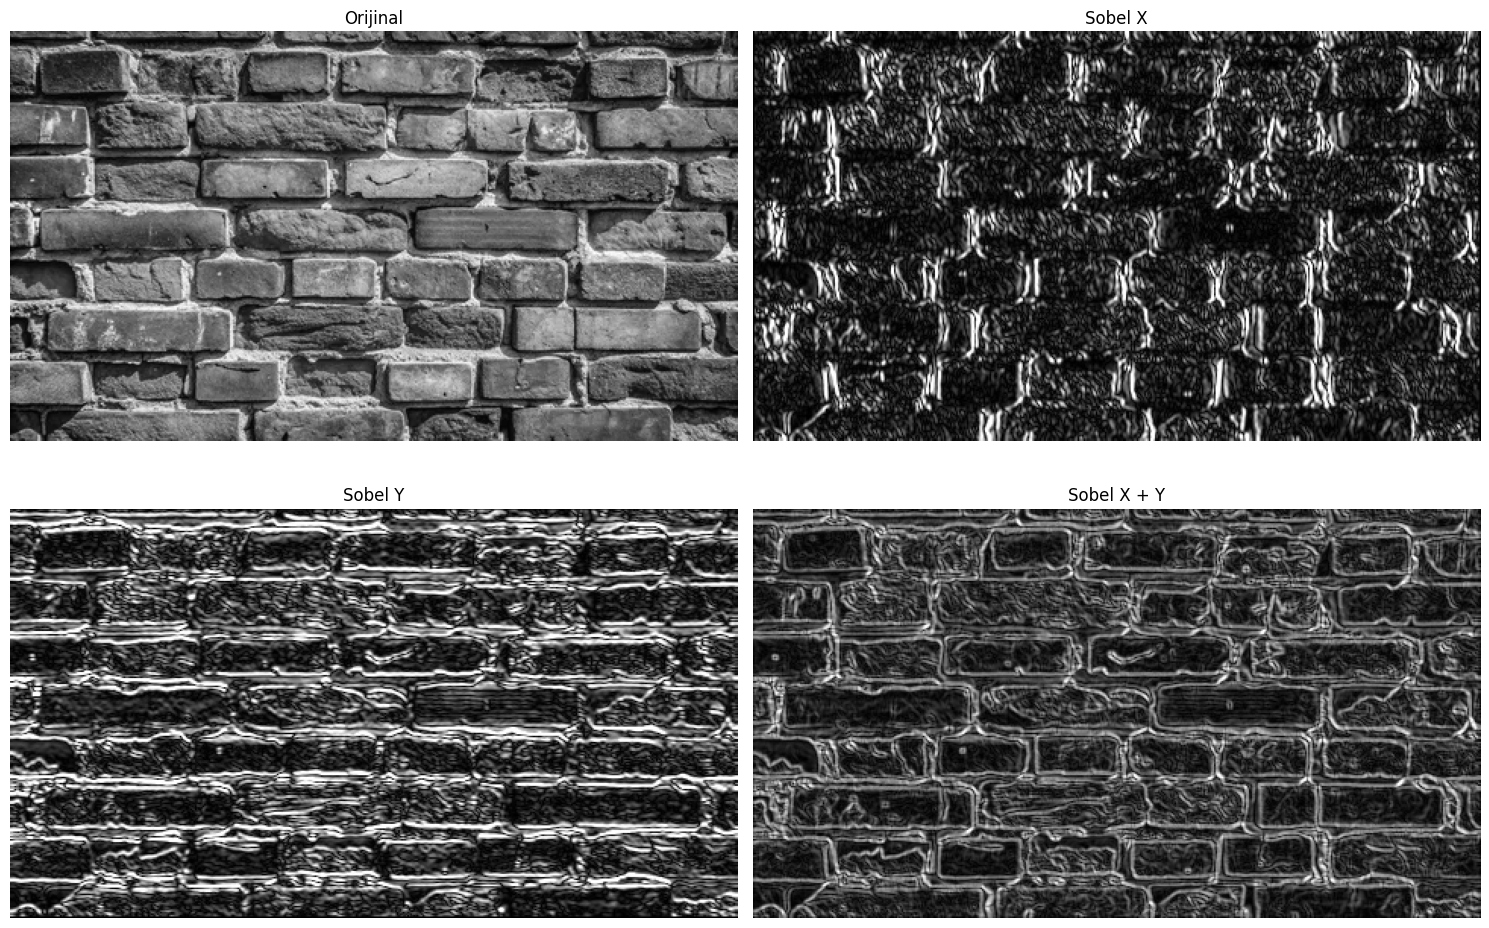

In [22]:
import cv2
import matplotlib.pyplot as plt

# Görüntüleri oku
orijinal = cv2.imread('test', cv2.IMREAD_GRAYSCALE)
sobel_x = cv2.imread('sobel_x_sonuc.jpg', cv2.IMREAD_GRAYSCALE)
sobel_y = cv2.imread('sobel_y_sonuc.jpg', cv2.IMREAD_GRAYSCALE)
sobel_xy = cv2.imread('sobel_xy_sonuc.jpg', cv2.IMREAD_GRAYSCALE)

# Ekrana bas
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(orijinal, cmap='gray')
plt.title('Orijinal Görüntü')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(sobel_x, cmap='gray')
plt.title('Sobel X (Dikey Kenarlar)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(sobel_y, cmap='gray')
plt.title('Sobel Y (Yatay Kenarlar)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(sobel_xy, cmap='gray')
plt.title('Sobel X + Y (Tüm Kenarlar)')
plt.axis('off')

plt.tight_layout()
plt.show()